# 산불 탐지 프로젝트 · 데이터 가공과 전처리 (AI Hub 71330, 이진 분류)

**클래스** 양성(1) = 불꽃 또는 연기가 있는 사진 · 음성(0) = 불꽃·연기가 없는 정상 사진. 양성 안의 불꽃·연기 구분(`sub`)은 결과를 나눠 보려고 남긴다.
**근거** `eda.ipynb`(EDA)의 13절 '발견 → 전처리·실험 결정'과 다음 단계 목록. 여기서는 그 결정을 실제로 적용하고, 적용한 뒤의 데이터를 다시 잰다.

### 처리 순서

| 단계 | 내용 | 적용 범위 | 절 |
|---|---|---|---|
| 가공 1 · 라벨 변환 | 라벨 JSON(DB 이름 + 물체 박스) → 사진 한 장에 양성/음성 하나 | 전체 | 1 |
| 가공 2 · 제외 필터 | 합성 양성, 안 쓰는 양성 장소, 음성 속 연기(따로 보관), 지원하지 않는 해상도, 자르면 불·연기 박스가 없어지는 양성, 잘라도 시각 상자가 남는 카메라 | 전체 | 2 |
| 가공 3 · 분할 | 장소+촬영일 묶음 분할 `split_v2` (60 : 20 : 20) — 음성 묶음을 다시 배정해 기기·구름·안개 비율을 맞춤 | 전체 | 3 |
| 가공 4 · 라벨 정리 | 중복 박스 제거, 박스를 처리한 사진 좌표로 옮김, 방해 요소 면적을 자른 화면에서 다시 잼, 날짜·장소·조건 열 정리 | 전체 | 4 |
| 전처리 1 · 해상도 통일 | 3840×2160 → 1920×1080 (2×2 화소 평균) | 전체 | 5 |
| 전처리 2 · 글자 띠 제거 | 위 108px(10%) 자르기 → **1920×972** | 전체 | 5 |
| 데이터 통계 | 영상 수·길이, 클래스 비율, 정규화 값(채널 평균·표준편차) | 학습 | 6 |
| 확인 | 사진 42만 장 전부 실제로 처리, 지름길 다시 재기, 기기·밤 사진 점검 | | 5, 7 |
| 시험 묶음 | 가설 검증용: 방해 요소 종류·면적·장소별 시험 음성을 목록 열로 표시 | 시험 | 8 |

원본 JPEG는 다시 저장하지 않는다(다시 압축하면 손상이 섞이고, 42만 장을 다시 쓰면 수백 GB). 사진 처리는 `../wildfire_data.py`의 `preprocess()` 한 곳에 두고, 학습·평가 코드가 원천 zip에서 읽을 때마다 같은 함수를 부른다.

이 노트북은 **데이터 단계(가공·전처리)까지**다. 학습 때의 처리(영상당 N장 추출, 클래스 가중치·균형 추출, 증강)는 모델링 단계에서 정한다(코드 초안 `../modeling/`).

> 사진 출처: AI Hub(aihub.or.kr) 71330. 내부 분석에만 쓰고 재배포하지 않는다.

## 0. 준비

In [1]:
import os, sys, json, time, inspect, subprocess, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import Image as IImage, display

NB = os.path.abspath('')  # the kernel runs in notebooks/ (the builders set its path)
ROOT = os.path.dirname(NB)
sys.path[:0] = [NB, ROOT]
import eda_lib as E
import prep_lib as P
import wildfire_data as W

REBUILD = False          # True면 cache/를 무시하고 처음부터 다시 잰다
FIG = f'{W.PREP}/fig'
os.makedirs(FIG, exist_ok=True)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', None)

INK, INK2, SURFACE, GRID, NEUTRAL = '#1a1a19', '#52514e', '#fcfcfb', '#e8e7e3', '#6b6a65'
Y_NAME = {1: '양성', 0: '음성'}
Y_COLOR = {'양성': '#eb6834', '음성': '#1baf7a'}
SUB_COLOR = {'불꽃': '#eb6834', '연기': '#2a78d6', '정상': '#1baf7a'}
SPLITS = ['train', 'val', 'test']
SPLIT_KO = {'train': '학습', 'val': '검증', 'test': '시험'}
plt.rcParams.update({
    'font.family': ['Noto Sans CJK KR'], 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2bc', 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'font.size': 9.5, 'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 2})


def show_jpeg(b):
    display(IImage(data=b, format='jpeg'))


def pct(s):
    return round(100 * float(np.mean(s)), 1) if len(s) else np.nan


def with_total(t):
    t = t.copy()
    t.loc['합계'] = t.sum()
    return t


TAB = f'{W.PREP}/tables'
os.makedirs(TAB, exist_ok=True)


FACTS = {}   # 결과 정리 문서에 쓰는 낱개 수치 (마지막 칸에서 tables/facts.json으로 저장)


def save_tab(df, name):
    """결과 정리 문서가 숫자를 다시 옮겨 적지 않도록 표를 CSV로도 남긴다."""
    df.to_csv(f'{TAB}/{name}.csv')
    return df

## 1. 가공 1 · 라벨 변환: JSON → 사진 단위 양성/음성

AI Hub 라벨에는 사진 단위 클래스가 없다. DB 이름(`info.name` = 폴더 이름 앞부분)과 물체 박스로 정한다. 사람이 새로 붙인 라벨이 아니라 규칙으로 바꾼 것이다.

| 결과 | 규칙 |
|---|---|
| **양성** | `PositiveRealDB`이고 화염·흑색연기·백색/회색연기 박스가 하나라도 있음 (`sub` = 화염이 있으면 불꽃, 연기만 있으면 연기) |
| **음성** | `NegativeDB`이고 화염·연기 박스가 없음 (구름·안개/연무·굴뚝연기 박스만 있음) |
| 제외 · 합성 양성 | `PositiveSyntheticDB` (CCTV·드론 화면에 불꽃·연기를 붙여 넣은 사진) |
| 제외 · 안 쓰는 양성 장소 | 실제 양성 16곳 중 쓰지 않기로 한 12곳 (10/15 결정) |
| 따로 보관 · 음성 속 연기 | `NegativeDB`인데 연기 박스가 있음 (산불인지 판별 불확실 → 학습·시험에서 빼고 따로 보관) |

In [2]:
img, ann = E.aihub_labels(rebuild=REBUILD)
img = img.rename(columns={'split': 'official'})              # official = AI Hub 공식 분할 = 사진이 든 zip (train=TS, val=VS)
v2 = pd.read_csv(f'{E.REPORT}/split_v2.csv.gz', usecols=['path', 'split', 'group', 'block'])
img = img.merge(v2, on='path', how='left')                   # split = 장소+촬영일 분할 split_v2 (본 실험, 3절)

CATS = list(E.CAT.values())
cnt = (ann.drop_duplicates(['idx', 'cat', 'x', 'y', 'bw', 'bh']).assign(c=ann.cat.map(E.CAT))
       .groupby(['idx', 'c']).size().unstack(fill_value=0).reindex(columns=CATS, fill_value=0))
img = img.merge(cnt, left_on='idx', right_index=True, how='left')
img[CATS] = img[CATS].fillna(0).astype(int)

flame = img['화염'] > 0
smoke = (img['흑색연기'] + img['백색/회색연기']) > 0
real, neg = img.db.eq('PositiveRealDB'), img.db.eq('NegativeDB')
img['stage'] = np.select(
    [img.db.eq('PositiveSyntheticDB'), real & img.address.isin(E.DROP_POS_PLACES), neg & (flame | smoke), real & (flame | smoke), neg],
    ['제외: 합성 양성', '제외: 안 쓰는 양성 장소', '보관: 음성 속 연기', '양성', '음성'], default='?')
img['sub'] = np.select([flame, smoke], ['불꽃', '연기'], default='정상')
img['src'] = img.official
img['member'] = img.path.str.replace(r'\.json$', '.jpg', regex=True)   # 원천 zip 안의 사진 경로

print('규칙에 안 걸린 사진:', int((img.stage == '?').sum()), '/ 음성 DB 중 화염 박스가 있는 사진:', int((neg & flame).sum()))
print('장소+촬영일 분할에 든 사진이 모두 양성·음성·보관인가:',
      bool(img.loc[img.split.notna(), 'stage'].isin(['양성', '음성', '보관: 음성 속 연기']).all()),
      '/ 제외 사진은 분할 밖인가:', bool(img.loc[img.stage.str.startswith('제외'), 'split'].isna().all()))
save_tab(pd.crosstab(img.db, img.stage, margins=True, margins_name='합계'), 'label_rule')

규칙에 안 걸린 사진: 0 / 음성 DB 중 화염 박스가 있는 사진: 0
장소+촬영일 분할에 든 사진이 모두 양성·음성·보관인가: True / 제외 사진은 분할 밖인가: True


stage,보관: 음성 속 연기,양성,음성,제외: 안 쓰는 양성 장소,제외: 합성 양성,합계
db,,,,,,
NegativeDB,23729,0,156260,0,0,179989
PositiveRealDB,0,266383,0,57521,0,323904
PositiveSyntheticDB,0,0,0,0,126107,126107
합계,23729,266383,156260,57521,126107,630000


## 2. 가공 2 · 제외 필터

EDA에서 정한 제외 세 가지에 전처리 때문에 생기는 세 가지를 더한다.
- **지원하지 않는 해상도**: 1920×1080과 3840×2160(정확히 2배)만 같은 방법으로 1920×1080에 맞출 수 있다. 나머지 290장은 뺀다(EDA 6절).
- **자르면 불·연기 박스가 모두 없어지는 양성**: 위 10%를 자르면 박스가 그 띠 안에만 있던 사진은 정답(양성)의 근거가 화면에서 사라진다.
- **잘라도 시각 글자 상자가 남는 카메라**: 평창군대관령면 CCTV는 검은 시각 상자가 84~135px에 있어, 108px로 자르면 상자 아래쪽 28px(글자 아래 절반)가 남는다(5.3절). 다른 카메라의 글자는 모두 108px 안에 있어 자르는 높이는 그대로 두고 이 카메라 사진만 뺀다.

In [3]:
# 박스를 처리한 사진(1920×972) 좌표로 옮긴다. 같은 박스가 두 번 들어간 물체(EDA 3절)는 한 번만 둔다.
A = ann.drop_duplicates(['idx', 'cat', 'x', 'y', 'bw', 'bh']).merge(img[['idx', 'w']], on='idx')
x0, y0, x1, y1 = W.to_processed_xy(A.x.to_numpy(), A.y.to_numpy(), A.bw.to_numpy(), A.bh.to_numpy(), A.w.to_numpy())
A = A.assign(name=A.cat.map(E.CAT), x0=x0, y0=y0, x1=x1, y1=y1)
s_ = W.BASE_W / A.w                                           # 1920 폭 기준 배율 (4K = 0.5)
top_, h_ = A.y * s_, A.bh * s_
# 위 띠에 걸린 박스만: 박스 높이 중 자르는 선(108px) 아래에 남는 비율. 띠에 안 걸린 박스는 1
A['kept'] = np.where(top_ < W.CROP_TOP, ((top_ + h_ - W.CROP_TOP).clip(lower=0) / h_.where(h_ > 0)), 1.0).clip(0, 1)
FS = A[A.cat.isin([1, 2, 3])]
print('넓이가 0인 불·연기 박스:', int(((FS.bw <= 0) | (FS.bh <= 0)).sum()))
alive = FS.loc[(FS.x1 > FS.x0) & (FS.y1 > FS.y0), 'idx'].unique()

ok_res = (img.w.eq(1920) & img.h.eq(1080)) | (img.w.eq(3840) & img.h.eq(2160))
img['box_lost'] = img.stage.eq('양성') & ~img.idx.isin(alive)

rules = [('합성 양성', img.stage.eq('제외: 합성 양성')),
         ('안 쓰는 양성 장소 12곳', img.stage.eq('제외: 안 쓰는 양성 장소')),
         ("음성 속 연기 → '판별 불확실'로 따로 보관", img.stage.eq('보관: 음성 속 연기')),
         ('지원하지 않는 해상도 (1280×720 · 960×540 · 4032×1816)', ~ok_res),
         ('위 10%를 자르면 불·연기 박스가 모두 없어지는 양성', img.box_lost),
         ('잘라도 시각 글자 상자가 남는 카메라 (평창 CCTV)', img.address.eq('강원도평창군대관령면') & img.device.eq('cctv'))]
keep = pd.Series(True, index=img.index)
rows = [('라벨 JSON 전체', '', f'{len(img):,}')]
for name, drop in rules:
    d = keep & drop
    by = img.loc[d, 'stage'].replace({'보관: 음성 속 연기': '음성 DB'}).value_counts()
    rows.append((name, f'−{int(d.sum()):,}', f'{int((keep & ~drop).sum()):,}'))
    keep &= ~drop
waterfall = pd.DataFrame(rows, columns=['단계', '빼는 사진', '남는 사진'])
save_tab(waterfall, 'waterfall')
display(waterfall.style.hide(axis='index'))
FACTS['res_drop'] = img.loc[~ok_res & img.stage.isin(['양성', '음성', '보관: 음성 속 연기']), 'stage'].value_counts().to_dict()
FACTS['box_lost'] = img.loc[img.box_lost, 'sub'].value_counts().to_dict()
print('해상도로 뺀 사진의 결과:', img.loc[~ok_res & img.stage.isin(['양성', '음성', '보관: 음성 속 연기']), 'stage'].value_counts().to_dict(),
      '/ 박스가 없어지는 양성:', img.loc[img.box_lost, 'sub'].value_counts().to_dict())

M = img[keep].copy()                                          # 본 실험: 양성·음성
U = img[img.stage.eq('보관: 음성 속 연기') & ok_res].copy()      # 따로 보관: 판별 불확실
assert set(M.stage) == {'양성', '음성'} and M.split.notna().all() and U.split.notna().all()
M['y'] = M.stage.eq('양성').astype(int)
M['yname'] = M.y.map(Y_NAME)
FACTS.update(n_final=len(M), n_pos=int(M.y.sum()), n_neg=int((M.y == 0).sum()), n_uncertain=len(U))
print(f'본 실험 {len(M):,}장 (양성 {int(M.y.sum()):,} · 음성 {int((M.y == 0).sum()):,}), 따로 보관 {len(U):,}장')

넓이가 0인 불·연기 박스: 0


단계,빼는 사진,남는 사진
라벨 JSON 전체,,"630,000"
합성 양성,"−126,107","503,893"
안 쓰는 양성 장소 12곳,"−57,521","446,372"
음성 속 연기 → '판별 불확실'로 따로 보관,"−23,729","422,643"
지원하지 않는 해상도 (1280×720 · 960×540 · 4032×1816),−290,"422,353"
위 10%를 자르면 불·연기 박스가 모두 없어지는 양성,−45,"422,308"
잘라도 시각 글자 상자가 남는 카메라 (평창 CCTV),−23,"422,285"


해상도로 뺀 사진의 결과: {'음성': 290} / 박스가 없어지는 양성: {'연기': 40, '불꽃': 5}


본 실험 422,285장 (양성 266,338 · 음성 155,947), 따로 보관 23,729장


## 3. 가공 3 · 분할: 장소+촬영일 묶음 (split_v2)

공식 분할은 검증 사진의 98.7%가 같은 카메라의 학습 사진과 거의 같아(EDA 12절) 쓰지 않는다. 같은 장소·같은 날 사진을 한 **묶음**으로 두고, 묶음 단위로 학습·검증·시험에 60 : 20 : 20으로 나눈다.
같은 카메라가 이틀에 걸치거나 날짜 묶음끼리 거의 같은 사진이 있으면 한 묶음으로 합쳤다(`make_aihub_split.py`, 묶음 82개).

### 3.1 split_v1 → split_v2: 기기·구름·안개 비율 맞추기

EDA에서 쓴 split_v1은 비율을 맞출 층(클래스·낮밤·날씨·강릉 여부)에 **기기와 방해 요소가 없어**, 드론 음성 사진의 64%가 시험에 몰렸다(시험 음성의 63%가 드론, 학습 음성은 10%). 이대로면 시험 오경보율에 방해 요소 효과와 '학습에서 드물게 본 드론 시점' 효과가 섞인다.
`../make_aihub_split_v2.py`는 **양성이 든 묶음 13개는 그대로 두고**(양성 쪽 사진은 v1과 같다) **음성만 든 묶음 69개를 다시 배정**한다.
비율을 맞출 층에 드론, 안개 면적 ≥5%·≥20%, 구름 면적 ≥5%·≥20%, 굴뚝연기, 8~9월을 더하고(드론·안개≥20%·구름≥20%는 가중치 2), 시험의 진짜 안개(면적 ≥20%) 음성이 v1보다 적거나 그런 안개 장소가 시험에 3곳보다 적으면 벌점을 준다.
v1 배정과 무작위 배정 240개에서 시작해 묶음 옮기기·맞바꾸기를 반복하고, 검증·시험에서 층 비율이 20%에서 가장 멀리 벗어난 정도가 가장 작은 배정을 골랐다.

이렇게 정하기까지 두 번 고쳤다.
① 묶음을 가장 적게 옮기는 방법은 13개만 옮겨 드론은 맞췄지만, 구름 층을 보지 않아 시험의 구름 음성이 24%에서 13%로 줄었다.
② 구름·안개를 '박스가 있음'으로 세면, 안개가 아주 조금 걸친 큰 묶음(구정면 8/22, 안개 면적 중앙값 0.3%)이 시험의 안개 몫을 채워 진짜 안개 사진(평창·강동면모전리·홍제동 등)이 모두 검증으로 빠졌다(시험 '안개/연무만' 116장).
그래서 방해 요소 층은 **면적으로** 센다(8절 시험 묶음과 같은 기준). 참고로 v1은 검증에 안개(면적 ≥5%) 음성이 한 장도 없었다.

In [4]:
V1 = pd.read_csv(f'{E.REPORT}/split_v1.csv.gz', usecols=['path', 'split']).rename(columns={'split': 'split_v1'})
M = M.merge(V1, on='path', how='left')
neg = M[M.y == 0]
moved = (neg[neg.split != neg.split_v1].groupby('block')
         .agg(v1=('split_v1', 'first'), v2=('split', 'first'), 음성=('idx', 'size'),
              드론_pct=('device', lambda s: round(100 * (s == 'drone').mean())), 장소=('address', lambda s: E.short_place(s.iloc[0])))
         .sort_values(['v1', '음성'], ascending=[True, False]))
moved[['v1', 'v2']] = moved[['v1', 'v2']].replace(SPLIT_KO)
print(f'v1과 다른 분할로 간 음성 묶음 {len(moved)}개 / 69개, 음성 사진 {int(moved.음성.sum()):,}장 (양성 사진은 그대로:',
      bool((M.loc[M.y == 1, 'split'] == M.loc[M.y == 1, 'split_v1']).all()), ')')
display(save_tab(moved, 'split_moves'))
flow_tab = pd.crosstab(moved.v1, moved.v2, values=moved.음성, aggfunc='sum').fillna(0).astype(int)
flow_n = pd.crosstab(moved.v1, moved.v2)
print('옮긴 음성 사진 수 (행 = v1, 열 = v2)'); display(save_tab(flow_tab, 'split_flow')); save_tab(flow_n, 'split_flow_blocks')
summ = pd.read_csv(f'{E.REPORT}/split_v2_summary.csv').set_index(['층', '판'])
strata = summ[[f'{s}%' for s in SPLITS]].unstack('판')
strata.columns = [f'{SPLIT_KO[c[0][:-1]]} {c[1]}' for c in strata.columns]
strata = strata[[f'{SPLIT_KO[s]} {v}' for v in ('v1', 'v2') for s in SPLITS]]
print('음성 층마다 학습·검증·시험에 든 비율 (%, 목표 60 / 20 / 20)'); display(save_tab(strata, 'split_strata'))
dw = pd.DataFrame({v: neg.groupby(col).device.apply(lambda s: round(100 * (s == 'drone').mean(), 1)) for v, col in [('v1', 'split_v1'), ('v2', 'split')]}).T[SPLITS]
print('분할마다 음성 사진 중 드론 비율 (%)'); display(save_tab(dw.rename(columns=SPLIT_KO), 'split_drone'))
FACTS.update(n_moved_blocks=len(moved), n_moved_neg=int(moved.음성.sum()), drone_test_v1=float(dw.loc['v1', 'test']), drone_test_v2=float(dw.loc['v2', 'test']),
             drone_train_v1=float(dw.loc['v1', 'train']), drone_train_v2=float(dw.loc['v2', 'train']),
             fog_test_v1=int(summ.loc[('정상·안개≥20%', 'v1'), 'test']), fog_test_v2=int(summ.loc[('정상·안개≥20%', 'v2'), 'test']),
             fog_val_v1=int(summ.loc[('정상·안개≥5%', 'v1'), 'val']), fog_val_v2=int(summ.loc[('정상·안개≥5%', 'v2'), 'val']))

v1과 다른 분할로 간 음성 묶음 32개 / 69개, 음성 사진 61,679장 (양성 사진은 그대로: True )


,v1,v2,음성,드론_pct,장소
block,,,,,
강릉 장현동/20221017 + 강릉 장현동/20221018,시험,학습,7679,92,장현동
경기도광명시소하동/20221111 + 경기도광명시소하동/20221201,시험,검증,5564,100,광명시소하동
경기도안산시단원구/20221118,시험,학습,2454,100,안산시단원구
경기도파주시적성면/20221115,시험,학습,1170,0,파주시적성면
충북청주시상당구문의면/20221112,시험,학습,734,0,충북청주시상당구문의면
강릉 경포저수지/20221025,시험,검증,283,100,경포저수지
경기도광명시하얀동/20221118,시험,학습,247,100,광명시하얀동
강릉 대전동/20220801,시험,검증,123,100,대전동
강릉 장현저수지/20221015,시험,학습,68,100,장현저수지


옮긴 음성 사진 수 (행 = v1, 열 = v2)


v2,검증,시험,학습
v1,,,
검증,0,9014,13199
시험,6021,0,12352
학습,15290,5803,0


음성 층마다 학습·검증·시험에 든 비율 (%, 목표 60 / 20 / 20)


,학습 v1,검증 v1,시험 v1,학습 v2,검증 v2,시험 v2
층,,,,,,
neg_with_smoke,69.8,25.3,4.9,68.6,5.7,25.7
정상·8~9월,61.7,25.3,13.0,59.1,21.9,19.0
정상·강릉,59.2,17.5,23.3,63.0,18.1,18.9
정상·구름≥20%,35.8,28.1,36.2,58.3,20.0,21.7
정상·구름≥5%,52.2,23.3,24.4,61.0,20.1,18.8
정상·굴뚝연기,60.4,23.8,15.9,58.2,24.7,17.1
정상·그밖,60.0,20.1,19.9,62.4,18.9,18.8
정상·드론,29.7,6.6,63.8,59.6,20.1,20.3
정상·비,60.0,22.6,17.4,61.1,20.3,18.6


분할마다 음성 사진 중 드론 비율 (%)


,학습,검증,시험
v1,10.4,7.2,63.2
v2,19.9,22.6,22.6


### 3.2 누수 다시 재기

묶음은 거의 같은 사진이 있는 날짜 묶음끼리 이미 합쳐 둔 단위라 묶음째 옮겨도 새 누수는 생기지 않아야 한다. EDA 12절과 같은 척도로 확인한다(`../check_aihub_split.py`):
검증·시험 사진(분할·클래스당 2,000장)마다 **같은 장소의 학습 사진 전부**와 32×18 썸네일 평균 절대차를 재고, 6 미만이면 거의 같은 사진으로 센다.

In [5]:
chk = pd.concat([pd.read_csv(f'{E.REPORT}/split_{v}_check.csv').assign(판=v) for v in ('v1', 'v2')])
chk['label'] = chk.label.map({'fire': '불꽃', 'smoke': '연기', 'normal': '정상'})
leak = chk.groupby(['판', 'split', 'label']).agg(
    검사한_사진=('d', 'size'), 같은장소가_학습에_있음_pct=('d', lambda x: round(100 * np.isfinite(x).mean(), 1)),
    거의같음_pct=('d', lambda x: round(100 * (x < 6).mean(), 2)),
    차이_중앙값=('d', lambda x: round(float(np.median(x[np.isfinite(x)])), 1) if np.isfinite(x).any() else np.nan))
leak = leak.rename(index=SPLIT_KO, level=1).sort_index()
display(save_tab(leak, 'split_leak'))
FACTS.update(leak_v2_max_pct=float(leak.loc['v2', '거의같음_pct'].max()), leak_v2_n=int(leak.loc['v2', '검사한_사진'].sum()),
             leak_v2_near=int((chk[chk.판 == 'v2'].d < 6).sum()))

검사한_사진  같은장소가_학습에_있음_pct  거의같음_pct  차이_중앙값
판  split label                                            
v1 검증    불꽃       2000               9.6       0.0    18.4
         연기       2000              47.3       0.0    19.8
         정상       2000              35.2       0.0    12.7
   시험    불꽃       2000               5.2       0.0    24.9
         연기       2000              40.3       0.0    21.9
         정상       2000              30.0       0.0    36.8
v2 검증    불꽃       2000               9.6       0.0    18.4
         연기       2000              47.3       0.0    19.8
         정상       2000              30.0       0.0    11.4
   시험    불꽃       2000               5.2       0.0    24.9
         연기       2000              40.3       0.0    21.9
         정상       2000              18.4       0.0    17.9

### 3.3 분할별 사진 수

In [6]:
t = pd.crosstab([M.yname, M['sub']], M.split)[SPLITS]
t.loc[('양성', '합계'), :] = t.loc['양성'].sum()
t = t.sort_index(level=0, sort_remaining=False).reindex([('양성', '불꽃'), ('양성', '연기'), ('양성', '합계'), ('음성', '정상')])
t.loc[('전체', ''), :] = t.loc[[('양성', '합계'), ('음성', '정상')]].sum()
t['전체'] = t.sum(axis=1)
share = (100 * t.div(t.loc[('전체', '')], axis=1)).round(1)
split_tab = t.astype(int).rename(columns=SPLIT_KO)
display(save_tab(split_tab, 'split'))
print('분할 안 비율 (%)'); display(save_tab(share.rename(columns=SPLIT_KO), 'split_share'))
units = (M.assign(v=M.place_cam + '/' + M.video_fuel).groupby(['split', 'yname'])
         .agg(묶음=('block', 'nunique'), 장소=('address', 'nunique'), 영상=('v', 'nunique')).unstack('yname').reindex(SPLITS))
save_tab(units.rename(index=SPLIT_KO), 'split_units')

split          학습     검증     시험      전체
yname sub                              
양성    불꽃    49406   8560  28736   86702
      연기   110195  37550  31891  179636
      합계   159601  46110  60627  266338
음성    정상    97582  29008  29357  155947
전체         257183  75118  89984  422285

분할 안 비율 (%)


split         학습     검증     시험     전체
yname sub                            
양성    불꽃    19.2   11.4   31.9   20.5
      연기    42.8   50.0   35.4   42.5
      합계    62.1   61.4   67.4   63.1
음성    정상    37.9   38.6   32.6   36.9
전체         100.0  100.0  100.0  100.0

묶음     장소        영상      
yname 양성  음성 양성  음성    양성    음성
split                          
학습     5  27  2  25  5333  1034
검증     5  13  4  12  1787   212
시험     3  24  3  19  1801   470

## 4. 가공 4 · 라벨 정리

### 4.1 박스: 처리한 사진 좌표로 옮기기

모델이 보는 사진은 1920×972이므로 박스도 같은 좌표로 옮겨 둔다(박스 크기별 결과, 증강 범위 점검, 나중에 탐지로 바꿀 때 쓴다).
좌표 변환: `x' = x × 1920/원본 가로`, `y' = y × 1920/원본 가로 − 108`, 화면 밖은 자른다.

In [7]:
FSm = FS[FS.idx.isin(M.idx)]
cut = FSm[FSm.kept < 1]
print(f'불·연기 박스 {len(FSm):,}개 중 위 띠에 일부가 잘리는 박스 {len(cut):,}개 ({pct(FSm.kept < 1)}%, 사진 {cut.idx.nunique():,}장), '
      f'잘리는 박스에서 남는 높이 중앙값 {cut.kept.median() * 100:.0f}%')
print('잘리는 박스 (종류별):', cut.name.value_counts().to_dict())
FACTS.update(n_boxes=len(FSm), n_cut=len(cut), cut_pct=pct(FSm.kept < 1), cut_kept_median=round(float(cut.kept.median()) * 100, 1),
             cut_by_name=cut.name.value_counts().to_dict(), cut_images=int(cut.idx.nunique()))

# 사진마다 가장 큰 화염·연기 박스의 짧은 변 (처리한 사진 기준)
FSm = FSm.assign(short=np.minimum(FSm.x1 - FSm.x0, FSm.y1 - FSm.y0))
M = M.merge(FSm[FSm.cat == 3].groupby('idx').short.max().rename('fire_short'), left_on='idx', right_index=True, how='left')
M = M.merge(FSm[FSm.cat.isin([1, 2])].groupby('idx').short.max().rename('smoke_short'), left_on='idx', right_index=True, how='left')
bs = M[M.y == 1].groupby(['sub', 'split']).agg(가장큰화염_짧은변_중앙값=('fire_short', 'median'),
                                               가장큰연기_짧은변_중앙값=('smoke_short', 'median'),
                                               화염16px미만=('fire_short', lambda s: pct(s.dropna() < 16)))
save_tab(bs.round(1).rename(index=SPLIT_KO, level=1), 'box_size')

불·연기 박스 377,630개 중 위 띠에 일부가 잘리는 박스 91,542개 (24.2%, 사진 89,017장), 잘리는 박스에서 남는 높이 중앙값 80%


잘리는 박스 (종류별): {'백색/회색연기': 53434, '흑색연기': 38099, '화염': 9}


가장큰화염_짧은변_중앙값  가장큰연기_짧은변_중앙값  화염16px미만
sub split                                        
불꽃  시험              45.9          264.5       6.4
    학습              33.0          273.6      12.6
    검증              29.4          324.2      10.7
연기  시험               NaN          246.2       NaN
    학습               NaN          229.4       NaN
    검증               NaN          310.3       NaN

### 4.2 방해 요소 면적: 자른 화면에서 다시 재기

가설의 핵심 변수인 구름·안개/연무·굴뚝연기의 면적을 **모델이 보는 화면(1920×972)** 기준으로 다시 잰다. 위 10%에는 하늘이 많아, 자르면 구름 면적이 줄어든다.
EDA는 다각형 넓이를 더해 1로 잘랐지만, 여기서는 다각형을 1/4 격자(480×270)에 그려 **겹친 부분은 한 번만** 센다(합집합). segmentation이 빈 물체는 bbox로 그린다.

In [8]:
NEG = pd.concat([M[M.y == 0], U])
area = P.distractor_area(NEG[['idx', 'official', 'path', 'w']], REBUILD)
assert set(NEG.idx) <= set(area.idx)
EN = {'구름': 'cloud', '안개/연무': 'fog', '굴뚝연기': 'chimney', '구름안개': 'cloudfog'}
ren = {f'{p}_{k}': f'{p}_{v}' for k, v in EN.items() for p in ('full', 'crop')}
area = area.rename(columns=ren)
M = M.merge(area, on='idx', how='left')
U = U.merge(area, on='idx', how='left')

N = M[M.y == 0]
cmp = pd.DataFrame({k: [N[f'full_{v}'].gt(0).mean() * 100, N[f'crop_{v}'].gt(0).mean() * 100,
                        N.loc[N[f'full_{v}'] > 0, f'full_{v}'].median() * 100, N.loc[N[f'full_{v}'] > 0, f'crop_{v}'].median() * 100]
                    for k, v in EN.items()},
                   index=['있는 사진 % (원본)', '있는 사진 % (자른 뒤)', '면적 중앙값 % (원본)', '면적 중앙값 % (자른 뒤)']).round(1)
display(save_tab(cmp, 'area_cmp'))

BINS, BIN_LABELS = [-1, 5, 20, 101], ['<5%', '5~20%', '≥20%']
for c in ('full', 'crop'):
    M[f'bin_{c}'] = pd.cut(M[f'{c}_cloudfog'] * 100, BINS, labels=BIN_LABELS).astype(str).where(M.y == 0)
mv = pd.crosstab(M.loc[(M.y == 0) & (M.split == 'test'), 'bin_full'], M.loc[(M.y == 0) & (M.split == 'test'), 'bin_crop'])
print('시험 음성: 구름+안개 면적 구간 (행 = 원본 화면, 열 = 자른 화면)')
save_tab(mv.reindex(index=BIN_LABELS, columns=BIN_LABELS), 'area_bins_move')

,구름,안개/연무,굴뚝연기,구름안개
있는 사진 % (원본),58.6,29.2,34.2,76.2
있는 사진 % (자른 뒤),57.2,29.2,34.0,75.3
면적 중앙값 % (원본),19.5,17.1,1.2,21.6
면적 중앙값 % (자른 뒤),13.9,15.2,1.1,17.1


시험 음성: 구름+안개 면적 구간 (행 = 원본 화면, 열 = 자른 화면)


bin_crop,<5%,5~20%,≥20%
bin_full,,,
<5%,9615,8,0
5~20%,1740,3867,7
≥20%,0,3788,10332


In [9]:
# 방해 요소 종류 조합 (자른 화면에 실제로 남은 것만)
DIST = [('구름', 'cloud'), ('안개/연무', 'fog'), ('굴뚝연기', 'chimney')]
M['combo'] = ''
for k, v in DIST:
    M['combo'] = M.combo + np.where(M[f'crop_{v}'].fillna(0) > 0, ' + ' + k, '')
M['combo'] = M.combo.str.lstrip(' +').replace('', '(없음)').where(M.y == 0)
combo = pd.crosstab(M.combo, M.split)[SPLITS].rename(columns=SPLIT_KO)
combo['전체'] = combo.sum(axis=1)
combo = combo.sort_values('전체', ascending=False)
combo['%'] = (100 * combo.전체 / combo.전체.sum()).round(1)
print('자른 뒤 방해 요소가 하나도 남지 않은 음성:', int((M.combo == '(없음)').sum()), '장')
FACTS['no_distractor_after_crop'] = int((M.combo == '(없음)').sum())
save_tab(combo, 'combo')

자른 뒤 방해 요소가 하나도 남지 않은 음성: 988 장


split,학습,검증,시험,전체,%
combo,,,,,
구름,44886,7738,11585,64209,41.2
굴뚝연기,25510,2905,9058,37473,24.0
안개/연무,15517,386,4708,20611,13.2
구름 + 안개/연무,5413,7792,3963,17168,11.0
구름 + 굴뚝연기,5315,2497,2,7814,5.0
안개/연무 + 굴뚝연기,0,7668,8,7676,4.9
(없음),941,22,25,988,0.6
구름 + 안개/연무 + 굴뚝연기,0,0,8,8,0.0


### 4.3 촬영 조건 열 정리

- 날짜: 촬영 시각이 6가지 형식으로 섞여 있어(EDA 3.1) 날짜만 `YYYYMMDD`로 바꿔 쓴다. 시각은 쓰지 않는다.
- 밤: 시간대 라벨의 '야간' 정상은 실제로 어둡지 않다(EDA 7.3). 처리한 사진의 실제 밝기로 `dark`를 붙인다(5.4절).
- GPS·고도: 강릉 밖 음성 사진 대부분이 솔향수목원 좌표 하나로 들어가 있어(EDA 3.1) 쓰지 않는다.

In [10]:
for D in (M, U):
    D['date'] = D.datetime.map(E.norm_date)
    D['month'] = D.date.str[4:6].astype(int)
    D['place'] = D.address.map(E.short_place)
    D['gangneung'] = D.address.str.startswith('강원도강릉시')
    D['vid'] = D.place_cam + '/' + D.video_fuel
    D['orig_w'], D['orig_h'] = D.w, D.h
    D['dist_m'] = pd.to_numeric(D.distance, errors='coerce')
print('날짜로 못 바꾼 사진:', int(M.date.isna().sum() + U.date.isna().sum()))
print('기기:', M.device.value_counts().to_dict())
print('날씨:', M.weather.value_counts().to_dict())

날짜로 못 바꾼 사진: 0
기기: {'gopro': 343726, 'drone': 68520, 'phone': 5065, 'cctv': 4974}
날씨: {'맑음': 191913, '비': 117118, '흐림': 113254}


## 5. 전처리 1·2 · 해상도 통일과 글자 띠 제거

### 5.1 처리 함수

학습·검증·시험에 같은 함수를 쓴다(`../wildfire_data.py`).

In [11]:
print(f'처리 후 크기 {W.OUT_W}×{W.OUT_H}, 자르는 높이 {W.CROP_TOP}px (1920×1080 기준)\n')
print(inspect.getsource(W.preprocess))
print(inspect.getsource(W.to_processed_xy))

처리 후 크기 1920×972, 자르는 높이 108px (1920×1080 기준)

def preprocess(jpeg_bytes):
    """원천 JPEG 바이트 → 1920×972 RGB PIL 사진. 1920×1080·3840×2160만 받는다(나머지 해상도는 목록에서 뺐다)."""
    im = Image.open(io.BytesIO(jpeg_bytes)).convert('RGB')
    if im.size == (2 * BASE_W, 2 * BASE_H):
        im = im.reduce(2)                     # 2×2 화소 평균 (정확히 절반)
    elif im.size != (BASE_W, BASE_H):
        raise ValueError(f'지원하지 않는 해상도 {im.size}')
    return im.crop((0, CROP_TOP, OUT_W, BASE_H))

def to_processed_xy(x, y, w, h, orig_w):
    """원본 픽셀 좌표 박스 [x, y, w, h] → 처리한 사진(1920×972) 좌표 (x0, y0, x1, y1), 화면 밖은 자른다."""
    s = BASE_W / orig_w
    x0, x1 = np.clip(x * s, 0, OUT_W), np.clip((x + w) * s, 0, OUT_W)
    y0, y1 = np.clip(y * s - CROP_TOP, 0, OUT_H), np.clip((y + h) * s - CROP_TOP, 0, OUT_H)
    return x0, y0, x1, y1



### 5.2 처리 전·후

왼쪽 = 원본(어둡게 칠한 띠가 잘려 나가는 위 10%, 빨간 선 = 자르는 위치), 오른쪽 = 모델에 들어가는 1920×972. 박스: 주황 = 화염, 파랑 = 연기, 흰색 = 구름·안개/연무·굴뚝연기.

In [12]:
def pair_rows(rows, tw=560):
    tiles = []
    for r in rows.itertuples():
        bx = A[A.idx == r.idx]
        bx = [(b.x0, b.y0, b.x1, b.y1, b.name) for b in bx.itertuples() if b.x1 > b.x0 and b.y1 > b.y0]
        a, p, size = P.before_after(r, bx, tw)
        tiles.append((a, p, f'{r.yname}({r.sub}) · {r.device} · 원본 {size[0]}×{size[1]}', f'처리 후 {W.OUT_W}×{W.OUT_H}'))
    H = sum(t[0].height + 26 for t in tiles) + 4
    S = Image.new('RGB', (2 * tw + 12, H), '#ffffff')
    d = ImageDraw.Draw(S); y = 4
    for a, p, c1, c2 in tiles:
        S.paste(a, (4, y)); S.paste(p, (tw + 8, y))
        d.text((6, y + a.height + 3), c1, fill='#1a1a19', font=E._font(14))
        d.text((tw + 10, y + a.height + 3), c2, fill='#1a1a19', font=E._font(14))
        y += a.height + 26
    buf = io.BytesIO(); S.save(buf, 'JPEG', quality=85)
    return buf.getvalue()

# 드론 사진 왼쪽 위 날짜·GPS 글자 점수(원본 전수 측정, EDA 10절): 100 넘으면 글자 있음
txt = pd.concat([pd.read_csv(f'{E.REPORT}/img_{s}.csv.gz', usecols=['jpg', 'text']).assign(src=s) for s in ('train', 'val')])
M['jpg_name'] = M.member.str.rsplit('/', n=1).str[-1]
M = M.drop(columns='text_score', errors='ignore').merge(txt.rename(columns={'jpg': 'jpg_name', 'text': 'text_score'}),
                                                        on=['src', 'jpg_name'], how='left')
ex = pd.concat([
    M[(M['sub'] == '불꽃') & (M.device == 'gopro') & (M.fire_short.between(25, 60))].sample(1, random_state=1),
    M[(M['sub'] == '연기') & (M.device == 'drone') & (M.text_score > 100)].sample(1, random_state=1),
    M[(M.y == 0) & (M.device == 'cctv') & (M.crop_cloudfog > 0.2)].sample(1, random_state=2),
    M[(M.y == 0) & (M.orig_w == 3840) & (M.crop_fog > 0.2)].sample(1, random_state=1)])
b = pair_rows(ex)
open(f'{FIG}/before_after.jpg', 'wb').write(b)
show_jpeg(b)

[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


### 5.3 글자 띠 확인: 카메라마다 한 장씩 맨 위 150px

카메라(장소·카메라ID)마다 사진 한 장을 골라 맨 위 150px만 모았다. 빨간 선 아래(남는 부분)에 날짜·시각·GPS 글자가 내려오는 카메라가 있는지 눈으로 본다.
CCTV는 검은 시각 상자의 세로 위치를 숫자로도 잰다(밝기 40 미만 화소가 절반 넘는 줄).
아래 격자는 2절 필터 뒤의 목록으로 만들어, 빼기로 한 평창 CCTV는 들어 있지 않다.

In [13]:
cams = pd.concat([M, U]).groupby(['address', 'camera_id', 'stage']).sample(1, random_state=0).sort_values(['stage', 'address'])
sheet, strips = P.top_strips(cams[['src', 'member']])
open(f'{FIG}/top_strips.jpg', 'wb').write(sheet)
# 드론 사진 왼쪽 위 날짜·GPS 글자(원본 전수 측정 점수 > 100)가 있는 비율 — 자르기 전에는 클래스마다 크게 다르다
tx = M.assign(글자=M.text_score > 100).groupby(['device', 'orig_w', 'yname']).글자.agg(['sum', 'size'])
tx['%'] = (100 * tx['sum'] / tx['size']).round(1)
display(save_tab(tx[tx['sum'] > 0].rename(columns={'sum': '글자 있음', 'size': '사진'}), 'corner_text'))
print(f'카메라·결과 조합 {len(cams)}개:', cams.stage.value_counts().to_dict())
FACTS.update(n_cams=len(cams), cams_by_stage=cams.stage.value_counts().to_dict(),
             cams_cctv=int((cams.device == 'cctv').sum()), cams_text=int(((cams.device == 'cctv') | (cams.text_score > 100)).sum()))
cams[['address', 'camera_id', 'stage', 'device', 'src', 'member', 'text_score']].to_csv(f'{TAB}/cams.csv', index=False)
# CCTV 검은 시각 상자의 세로 위치 (필터 전 전체 사진에서, 카메라마다 6장)
box_rows = []
for (addr, cam), g in img[img.device.eq('cctv') & img.stage.isin(['음성', '보관: 음성 속 연기'])].groupby(['address', 'camera_id']):
    for r in g.sample(min(6, len(g)), random_state=0).itertuples():
        a = np.asarray(Image.open(io.BytesIO(E.image_zip(r.src).read(r.member))).convert('L'), dtype=float)[:220, 40:700]
        rr = np.where((a < 40).mean(1) > 0.5)[0]
        box_rows.append((E.short_place(addr), cam, len(g), int(rr.min()) if len(rr) else None, int(rr.max()) if len(rr) else None))
cbox = (pd.DataFrame(box_rows, columns=['장소', '카메라', '사진', '상자 위', '상자 아래']).groupby(['장소', '카메라'])
        .agg(사진=('사진', 'first'), 상자_위=('상자 위', 'min'), 상자_아래=('상자 아래', 'max')))
print('CCTV 검은 시각 상자 세로 위치 (px, 1920×1080 기준, 없으면 빈칸 — 흰 글자 시각은 0~45px)')
display(save_tab(cbox, 'cctv_box'))
show_jpeg(sheet)

글자 있음     사진     %
device orig_w yname                    
drone  1920   양성      7694  11909  64.6
              음성      1145   3342  34.3

카메라·결과 조합 392개: {'음성': 204, '양성': 141, '보관: 음성 속 연기': 47}


CCTV 검은 시각 상자 세로 위치 (px, 1920×1080 기준, 없으면 빈칸 — 흰 글자 시각은 0~45px)


사진  상자_위  상자_아래
장소      카메라                        
강동면모전리  BC002001   614   NaN    NaN
        BC002021  1086   NaN    NaN
사천면석교리  BC003021   530   NaN    NaN
        BC011021   536   NaN    NaN
옥계면금진리  BC007021  1188   NaN    NaN
옥계면남양리  BC008011   325  42.0   93.0
평창군대관령면 BC004011    23  84.0  135.0
홍제동     BC010011   274   NaN    NaN
        BC010012   230   NaN    NaN
        BC010021    67   NaN    NaN
        BC010022   124   NaN    NaN

[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


### 5.4 본 실험 사진 전부 처리해 보기

본 실험 사진 전부를 원천 zip에서 읽어 `preprocess()`를 실제로 돌린다. 크기가 모두 1920×972인지, 오류가 없는지, 한 장에 얼마나 걸리는지 확인하고,
처리한 사진의 픽셀 통계(EDA 10절과 같은 정의)와 채널 평균을 잰다. 18개 프로세스로 처음 한 번만 돌리고 결과는 `cache/`에 남긴다.

In [14]:
t0 = time.time()
items = M[['idx', 'src', 'member']].rename(columns={'idx': 'key'})
PS = P.process_all(items, REBUILD)
PS = PS[PS.key.isin(M.idx)]                  # 캐시는 처음 목록 기준(평창 CCTV 23장 포함)
assert set(PS.key) == set(M.idx)
print(f'처리한 사진 {len(PS):,}장, 오류 {int(PS["error"].notna().sum()) if "error" in PS else 0}장, 걸린 시간(캐시 포함) {time.time() - t0:.0f}초')
print('처리 후 크기:', PS.groupby(['out_w', 'out_h']).size().to_dict())
FACTS.update(n_processed=len(PS), n_errors=int(PS['error'].notna().sum()) if 'error' in PS else 0,
             out_sizes={f'{int(w)}x{int(h)}': int(c) for (w, h), c in PS.groupby(['out_w', 'out_h']).size().items()},
             cpu_hours=round(float((PS.t_read + PS.t_prep).sum()) / 3600, 2))
PS = PS.rename(columns={c: f'p_{c}' for c in PS.columns if c != 'key'})
M = M.merge(PS, left_on='idx', right_on='key', how='left').drop(columns='key')
tm = M.groupby('orig_w')[['p_t_read', 'p_t_prep']].median().mul(1000).round(1)
tm.index = [f'{w}×{w * 9 // 16}' for w in tm.index]
tm.columns = ['zip에서 읽기 (ms)', '처리 (ms)']
print('한 장당 걸린 시간 중앙값'); save_tab(tm, 'timing')

처리한 사진 422,285장, 오류 0장, 걸린 시간(캐시 포함) 0초
처리 후 크기: {(1920, 972): 422285}
한 장당 걸린 시간 중앙값


,zip에서 읽기 (ms),처리 (ms)
1920×1080,5.6,15.9
3840×2160,16.6,60.9


## 6. 목록 저장과 데이터 통계

### 6.1 목록(manifest) 저장

학습·평가 코드는 이 목록만 읽으면 된다(`wildfire_data.load_manifest()`). `dark` = 처리한 사진의 밝기(짧은 변 256px로 줄인 회색조 평균)가 50 미만.

In [15]:
M['dark'] = M.p_bright < 50
COLS = ['split', 'y', 'sub', 'src', 'member', 'vid', 'place', 'address', 'gangneung', 'date', 'month', 'device', 'weather',
        'timezone', 'dist_m', 'orig_w', 'orig_h', 'dark', 'p_bright', 'fire_short', 'smoke_short',
        'crop_cloud', 'crop_fog', 'crop_chimney', 'crop_cloudfog', 'bin_crop', 'combo', 'group', 'block']
man = M[COLS].rename(columns={'bin_crop': 'area_bin'}).sort_values(['split', 'y', 'vid', 'member']).reset_index(drop=True)
man.to_csv(W.MANIFEST, index=False)
uc = U[['split', 'src', 'member', 'vid', 'place', 'address', 'date', 'device', 'weather', 'crop_cloud', 'crop_fog', 'crop_chimney']]
uc.to_csv(f'{W.PREP}/uncertain.csv.gz', index=False)
keep_idx = set(M.idx) | set(U.idx)
bx = A[A.idx.isin(keep_idx) & (A.x1 > A.x0) & (A.y1 > A.y0)].merge(img[['idx', 'member']], on='idx')
bx[['member', 'name', 'x0', 'y0', 'x1', 'y1']].round(1).to_csv(f'{W.PREP}/boxes.csv.gz', index=False)
print(f'manifest {len(man):,}줄 · uncertain {len(uc):,}줄 · boxes {len(bx):,}줄 → {W.PREP}')
man.head(3).T

manifest 422,285줄 · uncertain 23,729줄 · boxes 749,195줄 → prep


,0,1,2
split,test,test,test
y,0,0,0
sub,정상,정상,정상
src,train,train,train
member,NegativeDB_구름/강원도강릉시강동면모전리_BC002001/001_없음/NegativeDB_구름_강원도강릉시강동면모전리_BC002001_001_없음_00000001.jpg,NegativeDB_구름/강원도강릉시강동면모전리_BC002001/001_없음/NegativeDB_구름_강원도강릉시강동면모전리_BC002001_001_없음_00000061.jpg,NegativeDB_구름/강원도강릉시강동면모전리_BC002001/001_없음/NegativeDB_구름_강원도강릉시강동면모전리_BC002001_001_없음_00000121.jpg
vid,강원도강릉시강동면모전리_BC002001/001_없음,강원도강릉시강동면모전리_BC002001/001_없음,강원도강릉시강동면모전리_BC002001/001_없음
place,강동면모전리,강동면모전리,강동면모전리
address,강원도강릉시강동면모전리,강원도강릉시강동면모전리,강원도강릉시강동면모전리
gangneung,True,True,True
date,20220822,20220822,20220822


### 6.2 모델링에 넘길 데이터 특성: 영상 길이와 클래스 비율

같은 영상의 이웃 프레임은 거의 같은 사진이고(EDA 12절), 클래스 비율도 분할마다 조금씩 다르다. 이것을 어떻게 다룰지(영상당 추출 수, 클래스 가중치·균형 추출)는 학습 설정이라 모델링 단계에서 정한다. 여기서는 그때 필요한 숫자만 잰다.

In [16]:
vids = man.groupby(['split', 'y', 'vid']).size()
vt = vids.groupby(level=['split', 'y']).agg(['size', 'median', 'max']).rename(index=Y_NAME, level='y').rename(index=SPLIT_KO, level='split')
vt.columns = ['영상 수', '영상당 사진 중앙값', '가장 긴 영상']
vt = vt.reindex([(s, y) for s in ['학습', '검증', '시험'] for y in ['양성', '음성']])
display(save_tab(vt, 'videos'))
ratio = (pd.crosstab(man.split, man.y.map(Y_NAME), normalize='index') * 100).round(1).reindex(SPLITS).rename(index=SPLIT_KO)[['양성', '음성']]
print('분할마다 클래스 비율 (%)'); display(save_tab(ratio, 'class_ratio'))

영상 수  영상당 사진 중앙값  가장 긴 영상
split y                            
학습    양성  5333        23.0      319
      음성  1034        50.0     1012
검증    양성  1787        24.0      199
      음성   212        71.5      649
시험    양성  1801        25.0      142
      음성   470        28.0      625

분할마다 클래스 비율 (%)


y,양성,음성
split,,
학습,62.1,37.9
검증,61.4,38.6
시험,67.4,32.6


### 6.3 정규화 값

처리한 학습 사진 전부(1920×972)의 채널 평균·표준편차를 잰다. ImageNet 사전학습 모델은 사전학습 때의 ImageNet 값을 쓰는 것이 보통이라, 어떤 값을 쓸지는 모델을 고를 때 정한다.

In [17]:
T = M[M.split == 'train']
mean = [float(T[f'p_m_{c}'].mean()) for c in 'rgb']
std = [float(np.sqrt(T[f'p_q_{c}'].mean() - m ** 2)) for c, m in zip('rgb', mean)]
norm = pd.DataFrame({'학습 세트 평균': mean, 'ImageNet 평균': W.IMAGENET_MEAN, '학습 세트 표준편차': std, 'ImageNet 표준편차': W.IMAGENET_STD},
                    index=['R', 'G', 'B']).round(3)
json.dump({'train_mean': [round(v, 4) for v in mean], 'train_std': [round(v, 4) for v in std],
           'imagenet_mean': W.IMAGENET_MEAN, 'imagenet_std': W.IMAGENET_STD, 'n_train_images': len(T), 'split': 'split_v2'},
          open(f'{W.PREP}/norm_stats.json', 'w'), indent=1)
save_tab(norm, 'norm')

,학습 세트 평균,ImageNet 평균,학습 세트 표준편차,ImageNet 표준편차
R,0.384,0.485,0.256,0.229
G,0.385,0.456,0.252,0.224
B,0.345,0.406,0.265,0.225


## 7. 전처리 결과 확인

### 7.1 최종 데이터 구성

In [18]:
fin = pd.crosstab([man.y.map(Y_NAME), man['sub']], man.split)[SPLITS].rename(columns=SPLIT_KO)
fin['전체'] = fin.sum(axis=1)
fin.loc[('합계', ''), :] = fin.sum()
fin = fin.astype(int)
save_tab(fin, 'final')

split       학습     검증     시험      전체
y  sub                              
양성 불꽃    49406   8560  28736   86702
   연기   110195  37550  31891  179636
음성 정상    97582  29008  29357  155947
합계      257183  75118  89984  422285

### 7.2 지름길 다시 재기

EDA 11절과 같은 방법(깊이 2 결정 나무, 클래스 균형 가중치, 학습 쪽에서 만들고 검증·시험 쪽 균형 정확도)을 **이진 클래스**로 다시 잰다. 찍기 수준은 50%다.
- 처리 전: EDA의 10% 표본(원본 사진)에서 해상도·파일 크기(bpp)와 픽셀 값 7개
- 처리 후: 같은 사진을 처리한 1920×972에서 픽셀 값 7개. 모든 사진이 같은 크기라 해상도는 없어지고, 파일 크기는 모델이 보지 못하므로 뺀다.

In [19]:
PIX = ['bright', 'contrast', 'sat', 'sharp', 'dark_px', 'fire_px', 'gray_px']
SB = pd.read_parquet(f'{E.CACHE}/aihub_pixels_sample.parquet').rename(columns={'src': 'official', 'jpg': 'member'})
SB['short'] = SB[['w', 'h']].min(axis=1); SB['bpp'] = SB.nbytes * 8 / (SB.w * SB.h)
S = man[['split', 'y', 'src', 'member', 'device', 'orig_w']].merge(SB, left_on=['src', 'member'], right_on=['official', 'member'])
S = S.merge(M[['idx', 'src', 'member'] + [f'p_{c}' for c in PIX]], on=['src', 'member'])
print(f'표본 {len(S):,}장 (본 실험의 {100 * len(S) / len(man):.1f}%)')
FA = M[['split', 'y'] + [f'p_{c}' for c in PIX]]
cases = {'처리 전: 해상도·파일 크기': (S, ['short', 'bpp']), '처리 전: 전부 9개': (S, ['short', 'bpp'] + PIX),
         '처리 후: 픽셀 7개': (S, [f'p_{c}' for c in PIX]), '처리 후: 픽셀 7개 (전체 사진)': (FA, [f'p_{c}' for c in PIX])}
res, trees = {}, {}
for name, (D, feats) in cases.items():
    for te in ['val', 'test']:
        acc, desc = E.shortcut_tree(D[D.split == 'train'], D[D.split == te], feats, label='y')
        res.setdefault(name, {})[f'학습 → {SPLIT_KO[te]}'] = round(100 * acc, 1)
        trees[(name, te)] = desc
short_tab = pd.DataFrame(res).T
short_tab['찍기'] = 50.0
display(save_tab(short_tab, 'shortcut'))
open(f'{TAB}/shortcut_rule.txt', 'w').write(trees[('처리 후: 픽셀 7개 (전체 사진)', 'test')])
print('[처리 후: 픽셀 7개 (전체 사진) · 학습 → 시험] 찾은 규칙'); print(trees[('처리 후: 픽셀 7개 (전체 사진)', 'test')])

표본 43,453장 (본 실험의 10.3%)


,학습 → 검증,학습 → 시험,찍기
처리 전: 해상도·파일 크기,75.5,74.6,50.0
처리 전: 전부 9개,76.6,78.9,50.0
처리 후: 픽셀 7개,64.0,72.0,50.0
처리 후: 픽셀 7개 (전체 사진),64.4,71.8,50.0


[처리 후: 픽셀 7개 (전체 사진) · 학습 → 시험] 찾은 규칙
p_sharp < 1732
   p_bright < 48.74
      → 1
   p_bright ≥ 48.74
      → 0
p_sharp ≥ 1732
   p_fire_px < 0.004817
      → 1
   p_fire_px ≥ 0.004817
      → 0


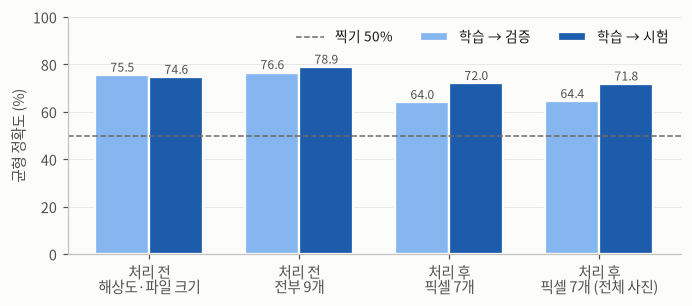

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 2.8))
cols = {'학습 → 검증': '#86b6ef', '학습 → 시험': '#1c5cab'}
x = np.arange(len(short_tab)); w = 0.36
for i, (c, col) in enumerate(cols.items()):
    xs = x + (i - 0.5) * w
    ax.bar(xs, short_tab[c], width=w, color=col, label=c, edgecolor=SURFACE, linewidth=1.5)
    for xi, v in zip(xs, short_tab[c]):
        ax.text(xi, v + 0.8, f'{v:.1f}', ha='center', va='bottom', fontsize=8, color=INK2)
ax.axhline(50, color=NEUTRAL, linewidth=1, linestyle='--', label='찍기 50%')
ax.set_xticks(x, [s.replace(': ', '\n') for s in short_tab.index]); ax.set_ylim(0, 100); ax.set_ylabel('균형 정확도 (%)')
ax.legend(loc='upper right', ncol=3); ax.grid(axis='y')
fig.savefig(f'{FIG}/shortcut.png', dpi=200, bbox_inches='tight'); plt.show()

### 7.3 기기: 4K 사진은 모두 드론 사진이다

해상도는 통일했지만, 3840×2160 사진은 모두 드론으로 찍은 것이다(카메라 하나가 두 해상도를 섞어 쓴 경우는 없다). 해상도 단서는 없앴어도 '드론 시점' 차이는 사진 내용에 남는다.
그래서 분할을 고쳐(3.1절) 드론 음성이 학습·검증·시험에 고르게 들어가게 했다. 아래는 고친 분할(split_v2)의 기기 비율이다.

In [21]:
dv = pd.crosstab([man.split.map(SPLIT_KO), man.y.map(Y_NAME)], man.device, normalize='index').mul(100).round(1)
dv = dv.reindex([(s, y) for s in ['학습', '검증', '시험'] for y in ['양성', '음성']])
print('분할·클래스별 기기 비율 (%)'); display(save_tab(dv, 'device'))
print('3840×2160 사진의 기기:', man.loc[man.orig_w == 3840, 'device'].value_counts().to_dict())
dr = M[M.device == 'drone'].groupby(['yname', 'orig_w']).p_sharp.median().unstack().round(0)
print('드론 사진: 처리 후 선명도(라플라시안 분산) 중앙값 — 열 = 원본 가로'); save_tab(dr, 'drone_sharp')

분할·클래스별 기기 비율 (%)


device    cctv  drone  gopro  phone
split y                            
학습    양성   0.0   13.9   86.1    0.0
      음성   0.5   19.9   75.3    4.3
검증    양성   0.0    5.1   94.9    0.0
      음성   2.9   22.6   72.6    1.9
시험    양성   0.0   18.8   81.2    0.0
      음성  12.2   22.6   64.0    1.2

3840×2160 사진의 기기: {'drone': 53269}
드론 사진: 처리 후 선명도(라플라시안 분산) 중앙값 — 열 = 원본 가로


orig_w,1920,3840
yname,,
양성,899.0,1798.0
음성,640.0,1218.0


#### 선택지 시험: 4K 출신 사진의 선명도 맞추기

2×2 평균으로 줄인 4K 사진은 같은 드론 사진이라도 원래 1920×1080 사진보다 선명도가 약 2배다(위 표). 7.2의 나무도 첫 가지를 선명도로 나눈다.
처리한 4K 출신 사진에 가우시안 블러(반경 1.25px)를 더하면 드론 1080 사진과 선명도가 비슷해진다. 10% 표본의 4K 사진에만 블러를 넣고 지름길을 다시 잰다.
**결정: 전처리에 넣지 않는다.** ① 블러를 넣으면 4K 출신 사진이 지상 카메라 1080 사진보다 오히려 훨씬 흐려져 반대 방향의 흔적이 생기고, ② 4K 사진의 작은 불꽃도 흐려지며,
③ 블러 자체가 평가용 손상의 한 종류와 겹친다. 이 흔적이 문제였던 것은 시험 음성 대부분이 4K 드론이었기 때문인데, 분할을 고쳐(3.1절) 드론 사진이 학습·검증·시험에 고르게 들어간다.
④ 고친 분할(split_v2)에서는 블러를 넣어도 지름길 정확도가 거의 그대로다(아래 표).

In [22]:
k4 = S[S.orig_w == 3840][['idx', 'src', 'member']].rename(columns={'idx': 'key'})
BL = P.blur_stats(k4, 1.25, REBUILD).set_index('key')
SBL = S.set_index('idx')
for c in PIX:
    SBL.loc[BL.index, f'p_{c}'] = BL[c]
SBL = SBL.reset_index()
blur_res = {}
for name, D in [('처리 후 (기본)', S), ('처리 후 + 4K 블러 1.25', SBL)]:
    for te in ['val', 'test']:
        acc, desc = E.shortcut_tree(D[D.split == 'train'], D[D.split == te], [f'p_{c}' for c in PIX], label='y')
        blur_res.setdefault(name, {})[f'학습 → {SPLIT_KO[te]}'] = round(100 * acc, 1)
    blur_res[name]['선명도 중앙값: 4K 출신'] = round(float(D.loc[D.orig_w == 3840, 'p_sharp'].median()))
    blur_res[name]['선명도 중앙값: 1080'] = round(float(D.loc[D.orig_w == 1920, 'p_sharp'].median()))
blur_tab = save_tab(pd.DataFrame(blur_res).T, 'blur4k')
print(f'표본의 4K 사진 {len(k4):,}장에 블러'); blur_tab

표본의 4K 사진 5,432장에 블러


,학습 → 검증,학습 → 시험,선명도 중앙값: 4K 출신,선명도 중앙값: 1080
처리 후 (기본),64.0,72.0,1590.0,2066.0
처리 후 + 4K 블러 1.25,62.7,72.2,826.0,2066.0


### 7.4 밤 사진

시간대 라벨의 '야간' 정상은 실제로 어둡지 않아(EDA 7.3) '어두우면 양성'을 배울 수 있다. 처리한 사진의 실제 밝기(위 띠를 잘라 하늘이 줄어든 화면)로 다시 센다.
**결정: 밤 정상을 만들지(인페인팅) 않는다.** 새 모델이 필요하고 지운 자국이 새 지름길이 될 수 있다. 대신 목록의 `dark` 열로 밤 결과를 따로 내고, 어두운 음성(대부분 새벽 사진)으로 '어두우면 양성'을 배웠는지 평가 때 확인한다.

In [23]:
dk = pd.crosstab([man.split.map(SPLIT_KO), man.y.map(Y_NAME)], man.dark).rename(columns={False: '밝음', True: '어두움'})
dk = dk.reindex([(s, y) for s in ['학습', '검증', '시험'] for y in ['양성', '음성']]).fillna(0).astype(int)
dk['어두운 비율 %'] = (100 * dk.어두움 / dk.sum(axis=1)).round(1)
display(save_tab(dk, 'dark'))
dn = man[(man.y == 0) & man.dark]
dnp = dn.groupby(['place', 'device', 'timezone']).size().sort_values(ascending=False).rename('어두운 음성').to_frame()
dnp['%'] = (100 * dnp['어두운 음성'] / len(dn)).round(1)
print('어두운 음성은 어디서 나오는가'); display(save_tab(dnp.head(6), 'dark_neg_places'))
rows = pd.concat([dn[dn.p_bright < 20].sample(4, random_state=0), dn[dn.p_bright >= 35].sample(4, random_state=0)])
show_jpeg(E.grid([dict(img=W.load_image(r), caption=f'{SPLIT_KO[r.split]} {r.place} {r.device} {r.timezone} 밝기 {r.p_bright:.0f}')
                  for r in rows.itertuples()], cols=4, tw=300))
FACTS.update(n_dark_neg=len(dn), dark_neg_top_place=dnp.index[0][0], dark_neg_top_pct=float(dnp['%'].iloc[0]),
             dark_neg_gujeong_pct=pct(dn.place == '구정면'))
FACTS.update(n_dark=int(man.dark.sum()), dark_pos_pct=pct(man.loc[man.dark, 'y'] == 1),
             min_neg_bright=round(float(man.loc[man.y == 0, 'p_bright'].min()), 1))
print(f'어두운 사진 {int(man.dark.sum()):,}장 중 양성 {pct(man.loc[man.dark, "y"] == 1)}% · 가장 어두운 음성 밝기 {man.loc[man.y == 0, "p_bright"].min():.1f}')

dark          밝음    어두움  어두운 비율 %
split y                          
학습    양성  135473  24128      15.1
      음성   96954    628       0.6
검증    양성   45552    558       1.2
      음성   26438   2570       8.9
시험    양성   45499  15128      25.0
      음성   29335     22       0.1

어두운 음성은 어디서 나오는가


어두운 음성     %
place       device timezone              
구정면         gopro  오전          2556  79.4
            drone  오전           346  10.7
성산면         gopro  오전           240   7.5
충북청주시상당구문의면 gopro  정오            29   0.9
옥천면         gopro  오전            22   0.7
경포저수지       gopro  오전            14   0.4

어두운 사진 43,034장 중 양성 92.5% · 가장 어두운 음성 밝기 2.7


[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


## 8. 가설 검증용 시험 묶음

가설 '구름·안개 같은 방해 요소가 오경보를 늘린다'는 **시험 음성 사진의 오경보율**(음성인데 양성으로 판정한 비율)을 아래 묶음별로 비교해 확인한다.
묶음은 목록의 열로 바로 고를 수 있게 pandas 조건식으로 저장한다(`prep/test_groups.csv`). 양성 쪽 묶음(불꽃/연기, 밤, 박스 크기)은 Recall을 나눠 볼 때 쓴다.

In [24]:
G = [('음성 전체', 'y == 0'),
     ('구름만', "y == 0 and combo == '구름'"), ('안개/연무만', "y == 0 and combo == '안개/연무'"), ('굴뚝연기만', "y == 0 and combo == '굴뚝연기'"),
     ('두 가지 이상', "y == 0 and combo.str.contains(' + ', regex=False)"), ('자른 뒤 방해 요소 없음', "y == 0 and combo == '(없음)'"),
     ('구름+안개 면적 <5%', "y == 0 and area_bin == '<5%'"), ('구름+안개 면적 5~20%', "y == 0 and area_bin == '5~20%'"),
     ('구름+안개 면적 ≥20%', "y == 0 and area_bin == '≥20%'"),
     ('안개/연무 면적 ≥20%', 'y == 0 and crop_fog >= 0.2'), ('구름 면적 ≥20%', 'y == 0 and crop_cloud >= 0.2'),
     ('강릉 음성', 'y == 0 and gangneung'), ('강릉 밖 음성', 'y == 0 and not gangneung'),
     ('8~9월 음성 (양성과 같은 계절)', 'y == 0 and month in [8, 9]'), ('드론 음성', "y == 0 and device == 'drone'"),
     ('양성 전체', 'y == 1'), ('양성 · 불꽃', "y == 1 and sub == '불꽃'"), ('양성 · 연기', "y == 1 and sub == '연기'"),
     ('양성 · 어두움', 'y == 1 and dark'), ('양성 · 화염 짧은 변 <16px', 'y == 1 and fire_short < 16')]
te = man[man.split == 'test']
rows = []
for name, q in G:
    g = te.query(q, engine='python')
    rows.append((name, q, len(g), g.place.nunique(), g.vid.nunique()))
groups = pd.DataFrame(rows, columns=['묶음', '조건 (pandas query)', '시험 사진', '장소', '영상'])
groups.to_csv(f'{W.PREP}/test_groups.csv', index=False)
save_tab(groups, 'test_groups')
groups.drop(columns='조건 (pandas query)')

,묶음,시험 사진,장소,영상
0,음성 전체,29357,19,470
1,구름만,11585,17,224
2,안개/연무만,4708,6,52
3,굴뚝연기만,9058,3,89
4,두 가지 이상,3981,8,121
5,자른 뒤 방해 요소 없음,25,2,6
6,구름+안개 면적 <5%,11355,13,157
7,구름+안개 면적 5~20%,7663,16,202
8,구름+안개 면적 ≥20%,10339,15,193
9,안개/연무 면적 ≥20%,3524,6,37


In [25]:
# 안개/연무 음성은 장소가 적다 → 장소별로도 본다
fogp = te[(te.y == 0) & (te.crop_fog > 0)].groupby('place').agg(사진=('member', 'size'), 영상=('vid', 'nunique'),
                                                              안개면적중앙값=('crop_fog', lambda s: round(100 * s.median(), 1)))
save_tab(fogp.sort_values('사진', ascending=False), 'fog_places')

,사진,영상,안개면적중앙값
place,,,
삼척시교동,2166,27,6.2
평창군대관령면,1624,20,23.2
강동면모전리,1399,4,17.6
옥계면금진리,1188,3,80.3
옥천면,1097,47,0.8
홍제동,504,5,33.0
내곡동,451,45,1.4
구정면,210,8,5.9
성산면,40,4,8.8


## 9. 산출물, 정한 것, 다음 단계로 넘기는 것

In [26]:
json.dump(FACTS, open(f'{TAB}/facts.json', 'w'), ensure_ascii=False, indent=1, default=str)
files = ['manifest.csv.gz', 'uncertain.csv.gz', 'boxes.csv.gz', 'norm_stats.json', 'test_groups.csv']
pd.DataFrame([(f, f'{os.path.getsize(f"{W.PREP}/{f}") / 1e6:.2f} MB') for f in files], columns=['prep/ 파일', '크기'])

,prep/ 파일,크기
0,manifest.csv.gz,9.32 MB
1,uncertain.csv.gz,0.28 MB
2,boxes.csv.gz,9.30 MB
3,norm_stats.json,0.00 MB
4,test_groups.csv,0.00 MB


| 파일 | 내용 |
|---|---|
| `prep/manifest.csv.gz` | 본 실험 사진 한 장에 한 줄: 분할(split_v2), 라벨(y, sub), 원천 zip 위치(src, member), 영상, 장소, 날짜, 조건, 실제 밝기(dark), 박스 크기, 방해 요소 면적(자른 화면), 면적 구간 |
| `prep/uncertain.csv.gz` | 따로 보관한 '음성 속 연기'(판별 불확실) |
| `prep/boxes.csv.gz` | 처리한 사진(1920×972) 좌표의 박스 |
| `prep/norm_stats.json` | 정규화 값(학습 세트, ImageNet) |
| `prep/test_groups.csv` | 가설 검증용 시험 묶음과 고르는 조건식 |
| `../report/aihub/split_v2.csv.gz` | 장소+촬영일 묶음 분할(`../make_aihub_split_v2.py`), 누수 검사 `split_v2_check.csv` |
| `../wildfire_data.py` | `preprocess()`(해상도 통일 + 위 108px 자르기), 박스 좌표 변환, 원천 zip 읽기 |

**전처리에서 정한 것**
1. 분할: split_v1 → split_v2 (양성 묶음은 그대로, 음성 묶음 69개 중 32개가 다른 분할로 — 드론·구름·안개 비율 맞춤, 누수 0장, 3절)
2. 4K 출신 사진 블러: 넣지 않음 (7.3)
3. 밤 정상 만들기: 하지 않음, `dark` 열로 밤 결과를 따로 냄 (7.4)

**다음 단계로 넘기는 것**
- 모델링(학습 설정·튜닝 R3): 영상당 추출 수 N, 클래스 가중치 또는 균형 추출(6.2의 영상 길이·비율), 증강(색상 증강 포함), 정규화 값 선택(6.3). 코드 초안 `../modeling/`
- 평가: 합성 안개 1~5단계 시험 세트, 결과를 기기·밤·장소·면적 구간별로 나눠 보기(8절 묶음)